In [1]:
%matplotlib inline

from collections import OrderedDict
from importlib import reload
import os, sys

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import scipy.stats
import scipy.ndimage as nd

from astropy.wcs import WCS
from astropy.io import fits
from astropy.utils.data import get_pkg_data_filename

from astropy.table import Table
from astropy.stats import mad_std
from astropy.constants import iau2012 as const

from scipy.optimize import curve_fit
from sklearn import linear_model
from scipy.stats import spearmanr, gaussian_kde
import statsmodels.api as sm

#from utils_z0mgs import *
#from utils_astro import *
from utils_stats import *

sys.path.append(os.path.join(os.getenv('HOME'),'python'))

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
from shapely.geometry import Point
from shapely.ops import cascaded_union

from jsplottools.sun_plot_tools.general import mpl_setup
from jsplottools.sun_plot_tools.ax import *
from jsplottools.sun_plot_tools.fig import *
mpl_setup(figtype='paper-1/3')
params = {'legend.fontsize': 'x-large',          
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
plt.rcParams.update(params)

**Load the data**

In [2]:
from analysis_load_resolvedirir import *

/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = 

/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = 

/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = np.log10((y[ind]/x[ind]))
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:199: RuntimeWarning: invalid value encountered in log10
  logyx = 

7.7/MIPS =  1.3069223448716272
Filter:  f1000w
... lowres ratio  0.3757478623422432
... to 24  0.4910732773328259
... log scatter  0.06272063648018004
Filter:  f1130w
... lowres ratio  1.35014151659062
... to 24  1.7645301167711482
... log scatter  0.04849587567606544
Filter:  f2100w
... lowres ratio  0.6111374708805144
... to 24  0.7987092164820776
... log scatter  0.10586889127262283
Filter:  w3
... lowres ratio  0.6042640740391201
... to 24  0.7897262205648894
... log scatter  0.06102212130693634
Filter:  w4
... lowres ratio  0.8099161173822104
... to 24  1.0584974712784825
... log scatter  0.19708210763309383
Filter:  irac4
... lowres ratio  0.9990940722790373
... to 24  1.3057383676902625
... log scatter  0.0402994856008577
Filter:  mips24
... lowres ratio  0.7651564026921778
... to 24  1.0
... log scatter  0.13791120482238264

... median background  0.048401958176173515
... scatter  0.07951985635516651
... range  -0.028605526514123597  -  0.20333796480826644



/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:296: RuntimeWarning: divide by zero encountered in true_divide
  bin_rats = np.array(bins['50']/bins['xmid'])
/data/tycho/0/leroy.42/projects/phangs_jwst/code/analysis_load_resolvedirir.py:304: RuntimeWarning: invalid value encountered in log10
  lograts = np.log10(np.array(rats))


In [3]:
10.**0.04

1.096478196143185

**Make a couple statistical statements**

In [5]:
hires_rlist = []
hires_taglist = []
for this_tag in hires_varpairs:
    if this_tag.count('w4') > 0:
        continue
    hires_rlist.append(hires_varpairs[this_tag]['spearmanr'])
    hires_taglist.append(this_tag)
    
lores_rlist = []
lores_taglist = []
for this_tag in lores_varpairs:
    if this_tag.count('w4') > 0:
        continue
    lores_rlist.append(lores_varpairs[this_tag]['spearmanr'])
    lores_taglist.append(this_tag)
    
print("Median rank correlation - lores: ", np.median(np.array(lores_rlist)))
print("Minimum rank correlation - lores: ", np.min(np.array(lores_rlist)))
print("Worst rank correlation - lores: ", np.array(lores_taglist)[np.where(np.array(lores_rlist) < 0.8)])
print("Total rank correlations < 0.8: ", np.sum(np.array(lores_rlist) < 0.8), len(lores_rlist))

print("Median rank correlation - hires: ", np.median(np.array(hires_rlist)))
print("Minimum rank correlation - hires: ", np.min(np.array(hires_rlist)))
print("Worst rank correlation - hires: ", np.array(hires_taglist)[np.where(np.array(hires_rlist) < 0.8)])
print("Total rank correlations < 0.8: ", np.sum(np.array(hires_rlist) < 0.8), len(hires_rlist))

Median rank correlation - lores:  0.9507317728063334
Minimum rank correlation - lores:  0.6269241276304247
Worst rank correlation - lores:  ['f770w_f2100w_ic5332' 'f1000w_mips24_ngc0628' 'f1130w_f2100w_ic5332'
 'f2100w_f770w_ic5332' 'f2100w_f1130w_ic5332' 'f2100w_w3_ic5332'
 'f2100w_irac4_ic5332' 'w3_f2100w_ic5332' 'irac4_f2100w_ic5332'
 'mips24_f1000w_ngc0628']
Total rank correlations < 0.8:  10 188
Median rank correlation - hires:  0.9501977934508121
Minimum rank correlation - hires:  0.6231028263078351
Worst rank correlation - hires:  ['f770w_f2100w_ic5332' 'f1130w_f2100w_ic5332' 'f1130w_f2100w_ngc7496'
 'f2100w_f770w_ic5332' 'f2100w_f1130w_ic5332' 'f2100w_f1130w_ngc7496']
Total rank correlations < 0.8:  6 60


In [6]:
print(lores_varpairs['irac4_mips24_ngc0628']['slope'])
print(lores_varpairs['irac4_mips24_ic5332']['slope'])
print(lores_varpairs['irac4_mips24_ngc1365']['slope'])
print(lores_varpairs['irac4_mips24_all']['slope'])

0.7702097903593427
0.5539726227512167
0.7407607506321423
0.7704629989765736


**Plot the basic scaling relations**


This tag:  f770w_f1000w_all
... slope lores:  0.3757478623422432
... slope hires:  0.36835521153575757
... model:  0.3793990853975501


This tag:  f770w_irac4_all
... slope lores:  0.9990940722790373
... model:  1.0051535042433166


This tag:  f770w_f1130w_all
... slope lores:  1.35014151659062
... slope hires:  1.3299762478007437
... model:  1.7461045369807295


This tag:  w3_f770w_all
... slope lores:  1.5724285140154821
... model:  0.7733981995633491


This tag:  f770w_f2100w_all
... slope lores:  0.6111374708805144
... slope hires:  0.5477786439468086
... model:  0.6492936825210099


This tag:  f770w_mips24_all
... slope lores:  0.7651564026921778
... model:  0.7519621512383876



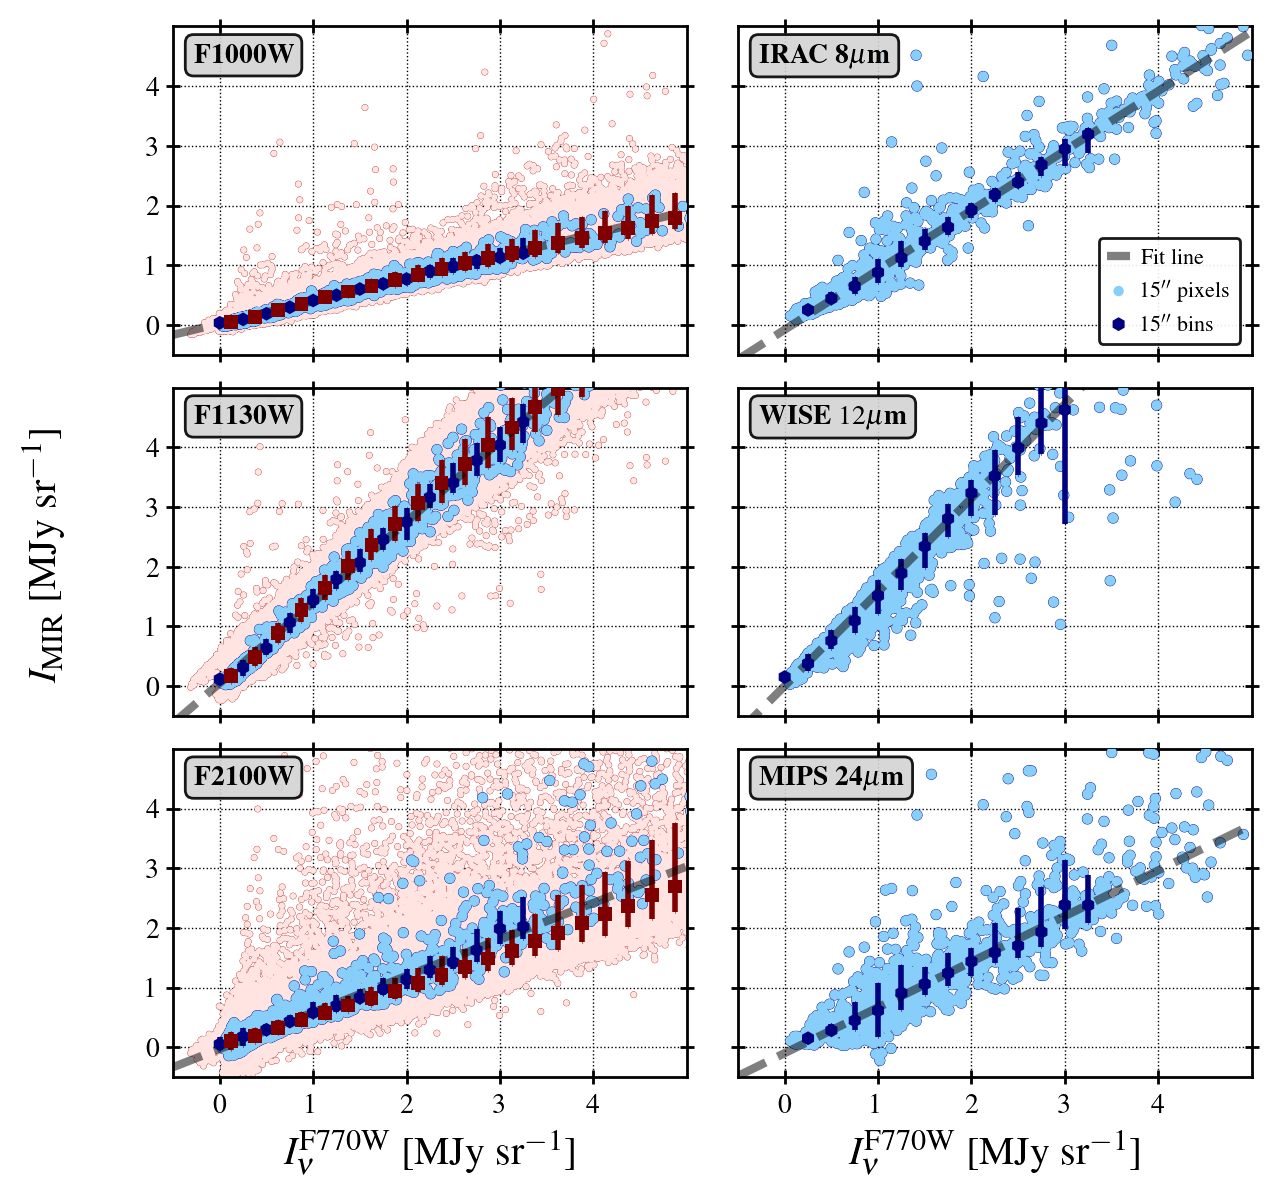

In [12]:
png_name = '../plots/jwst_miri_vs_miri.png'

npanels = 6
ncol = 2
nrow = 3
ticklength = 5

xmin = -0.5
xmax = +5.0
ymin = -0.5
ymax = +5.0
xticks = np.arange(0.,xmax,1.0)
yticks = np.arange(0.,ymax,1.0)

mpl_setup('paper-1/1', aspect=3./3., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

axes = axes.ravel()

xlabel_1 = r'$I_{\nu}^{\rm F770W}$ [MJy sr$^{-1}$]'
xlabel_2 = r'$I_{\nu}^{\rm F770W}$ [MJy sr$^{-1}$]'
ylabel = r'$I_{\rm MIR}$ [MJy sr$^{-1}$]'

fig.text(0.015, 0.5, ylabel, va='center', rotation='vertical', fontsize='large')

rows_done = 0
counter = 0

for iax, ax in enumerate(axes):
    
    axes[iax].set_xlim([xmin,xmax])
    axes[iax].set_xscale('linear')
    axes[iax].set_ylim([ymin,ymax])
    axes[iax].set_xticks(xticks)
    axes[iax].set_yticks(yticks)
    axes[iax].tick_params(direction='inout', length=ticklength)
    
    if counter == 4:
        axes[iax].set_xlabel(xlabel_1)    

    if counter == 5:
        axes[iax].set_xlabel(xlabel_2)    
        
    axes[iax].grid(True, linestyle='dotted',linewidth=0.5,color='black')
        
    if counter == 0:
        this_label = r'\textbf{F1000W}' #+'\n'+r'\textbf{vs. F770W}'
        this_lores_tag = 'f770w_f1000w_all'
        this_hires_tag = 'f770w_f1000w_all'
        draine_slope = (2.664E-25*10)/(9.119E-25*7.7)
        
    if counter == 2:
        this_label = r'\textbf{F1130W}' #+'\n'+r'\textbf{vs. F770W}'
        this_lores_tag = 'f770w_f1130w_all'
        this_hires_tag = 'f770w_f1130w_all'
        draine_slope = (1.085E-24*11.3)/(9.119E-25*7.7)
            
    if counter == 4:
        this_label = r'\textbf{F2100W}' #+'\n'+r'\textbf{vs. F770W}'
        this_lores_tag = 'f770w_f2100w_all'
        this_hires_tag = 'f770w_f2100w_all'
        draine_slope = (2.171E-25*21.)/(9.119E-25*7.7)
        
    if counter == 1:
        this_label = r'\textbf{IRAC 8$\mu$m}' #+'\n'+r'\textbf{vs. F770W}'
        this_lores_tag = 'f770w_irac4_all'        
        this_hires_tag = None
        #draine_slope = (7.391E-25*7.87)/(9.119E-25*7.7)
        draine_slope = (8.968E-25*7.87)/(9.119E-25*7.7)
        
    if counter == 3:
        this_label = r'\textbf{WISE $12\mu$m}' #+'\n'+r'\textbf{vs. F770W}'
        this_lores_tag = 'w3_f770w_all'        
        this_hires_tag = None
        #draine_slope = (4.464E-25*12.)/(9.119E-25*7.7)*(0.91) # includes color correction
        draine_slope = (4.973E-25*12.)/(9.119E-25*7.7)*(0.91) # includes color correction

    if counter == 5:
        this_label = r'\textbf{MIPS 24$\mu$m}' #+'\n'+r'\textbf{vs. F770W}'
        this_lores_tag = 'f770w_mips24_all'        
        this_hires_tag = None
        #draine_slope = (1.66E-25*24.)/(2.171E-25*21.)
        draine_slope = (2.20E-25*24.)/(9.119E-25*7.7)
        
    counter += 1
        
    d = lores_varpairs[this_lores_tag]
    loresx = d['x']
    loresy = d['y']               
    
    thresh = 10
    lores_bins = d['bins']
    lores_bin_ind = (lores_bins['counts_meas'] >= thresh)                    
    lores_bins = lores_bins[lores_bin_ind]
    lores_xb = lores_bins['xmid']
    lores_yb = (lores_bins['50'])
    lores_yblo = (lores_bins['16'])
    lores_ybhi = (lores_bins['84'])
    
    lores_m = d['slope']
    lores_b = d['intercept']
    
    ax.scatter(
        loresx, loresy, 
        marker='o', s=16, alpha=1.0,
        facecolor='navy', edgecolor='none',         
        zorder=3)

    ax.scatter(
        loresx, loresy, 
        marker='o', s=14, alpha=1.0,
        facecolor='lightskyblue', edgecolor='none',         
        zorder=4, label=r"$15''$ pixels")           

    if this_hires_tag is not None:
        d = hires_varpairs[this_hires_tag]
        hiresx = d['x']
        hiresy = d['y']               

        thresh = 10
        hires_bins = d['bins']
        hires_bin_ind = (hires_bins['counts_meas'] >= thresh)                    
        hires_bins = hires_bins[hires_bin_ind]
        hires_xb = hires_bins['xmid']
        hires_yb = (hires_bins['50'])
        hires_yblo = (hires_bins['16'])
        hires_ybhi = (hires_bins['84'])

        hires_m = d['slope']
        hires_b = d['intercept']

        ax.scatter(
            hiresx, hiresy, 
            marker='o', s=6, alpha=1.0,
            facecolor='firebrick', edgecolor='none',         
            zorder=1)

        ax.scatter(
            hiresx, hiresy, 
            marker='o', s=5, alpha=1.0,
            facecolor='mistyrose', edgecolor='none',         
            zorder=2, label=r"$1.67''$ pixels")               
    
    ax.errorbar(lores_xb,lores_yb,
                [(lores_yb-lores_yblo),
                 (lores_ybhi-lores_yb)],
               color='navy', capsize=0.1, elinewidth=2, fmt='none',
               zorder=6)

    ax.scatter(lores_xb, lores_yb, marker='h',s=25,
               edgecolor='none',facecolor='navy',zorder=7, label=r"$15''$ bins")    

    if this_hires_tag is not None:
        ax.errorbar(hires_xb,hires_yb,
                    [(hires_yb-hires_yblo),
                     (hires_ybhi-hires_yb)],
                   color='maroon', capsize=0.1, elinewidth=2, fmt='none',
                   zorder=6)

        ax.scatter(hires_xb, hires_yb, marker='s',s=25,
                   edgecolor='none',facecolor='maroon',zorder=7, label=r"$1.67''$ bins")
    
    # Line
    
    fidx = np.arange(xmin,xmax,0.01)
    ax.plot(fidx, fidx*lores_m + lores_b, linewidth=3, 
            color='black', zorder=6, alpha=0.5, linestyle='dashed', label=r'Fit line')    
    
    #if draine_slope is not None:
    #    ax.plot(fidx, fidx*draine_slope + 0.0, linewidth=3, 
    #        color='blueviolet', zorder=5, alpha=0.5, label=r'HD22 cirrus')    
    
    #if this_hires_tag is not None:
    #    ax.plot(fidx, fidx*hires_m + hires_b, linestyle='dashed', 
    #            linewidth=5, color='black', zorder=5, alpha=0.5)
    
    # Labels
    
    bbox_props = dict(boxstyle="round", fc="lightgray", ec='black',alpha=0.9)
    yval = 0.95
    va = 'top'
            
    ax.text(0.04, yval, this_label,
            ha='left', va=va,
            transform=ax.transAxes,
            size='small', bbox=bbox_props,
            zorder=5)

    #ax.tick_params(axis='both', which='major', length=2)
    #ax.tick_params(axis='both', which='minor', length=1)

    if counter == 2:
        ax.legend(fancybox=True, framealpha=0.9, loc='lower right', 
                  ncol=1, fontsize=8)    
    
    print("")
    print("This tag: ", this_lores_tag)
    print("... slope lores: ", lores_m)
    if this_hires_tag is not None:
        print("... slope hires: ", hires_m)
    print("... model: ", draine_slope)
    print("")
        
#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

**Print noise**

**Correlation Matrix**

In [6]:
png_name = '../plots/jwst_cohir_corr.png'

xbands = ['f770w','f1000w','f1130w','f2100w','co21']
xband_labels = [r'$7.7\mu$m',r'$10\mu$m',r'$11.3\mu$m',r'$21\mu$m',r'CO (2-1)']
ybands = ['co21','hacorr']
yband_labels = [r'CO (2-1)', r'H$\alpha^{\rm corr}$']

co_corrs = []
for this_band in xbands:
    if this_band == 'co21':
        co_corrs.append(np.nan)    
    else:
        co_corrs.append(varpairs['co21_'+this_band+'_all']['spearmanr'])
ha_corrs = []
for this_band in xbands:
    if this_band == 'co21':
        ha_corrs.append(varpairs['co21_hacorr_all']['spearmanr'])
    else:
        ha_corrs.append(varpairs['hacorr_'+this_band+'_all']['spearmanr'])

corr_im = np.transpose(np.array([co_corrs,ha_corrs],dtype=np.float))

mpl_setup('paper-1/2', aspect=3./5., fs=12)

fig, ax = plt.subplots()

ax.imshow(corr_im,cmap='Purples',vmin=0.0,vmax=1.0,aspect=0.25)
ax.set_yticks(np.arange(len(xbands)))
ax.set_yticklabels(xband_labels)

ax.set_xticks(np.arange(len(ybands)))
ax.set_xticklabels(yband_labels, rotation=45, ha="right",
         rotation_mode="anchor")

ax.plot([0.5,0.5],[-0.5,len(xbands)-0.5],color='k',linestyle='dotted')
for ii in np.arange(len(xbands)):
    yval = -0.5+ii
    ax.plot([-0.5,1.5],[yval,yval],color='k',linestyle='dotted')

for xx in range(len(ybands)):
    for yy in range(len(xbands)):
        this_text = r'$\rho=$'+f'{corr_im[yy,xx]:0.2f}'
        text = ax.text(xx, yy, this_text,
                       ha="center", va="center", color="w")    
    
#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

NameError: name 'varpairs' is not defined

In [8]:
10.**(-0.4), np.log10(5.5e9)

(0.3981071705534972, 9.740362689494244)